In [2]:
!pip install pandas seaborn matplotlib
!pip install scikit-learn kneed


[notice] A new release of pip is available: 24.0 -> 26.1
[notice] To update, run: C:\Users\katerina\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.1
[notice] To update, run: C:\Users\katerina\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


1. Подготовка наборов данных:
1.1. Загрузите наборы.
1.2. Проверьте корректность загрузки.
1.3. Постройте диаграмму рассеяния набора данных. Опишите форму данных, и особенности в данных.
1.4. Подготовьте наборы данных проведя стандартизацию или нормировку данных. Обоснуйте выбор операции.

In [3]:
#1.1
import pandas as pd

df_arcs = pd.read_csv("lab4_arcs.csv")
df_moons = pd.read_csv("lab4_moons.csv")

#1.2
display(df_arcs.head(5))
display(df_moons.head(5))

,Unnamed: 0,Power,MaxSpeed
0,0,238.26,209.08
1,1,259.27,312.22
2,2,233.45,277.00
3,3,237.04,311.72
4,4,279.28,326.99


,Unnamed: 0,Matches,AverageGoals
0,0,176.0,7.21
1,1,149.0,6.80
2,2,203.0,3.16
3,3,43.0,5.01
4,4,86.0,5.88


C:\Users\katerina\AppData\Local\Temp\ipykernel_12232\375480535.py:9: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=df,
C:\Users\katerina\AppData\Local\Temp\ipykernel_12232\375480535.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


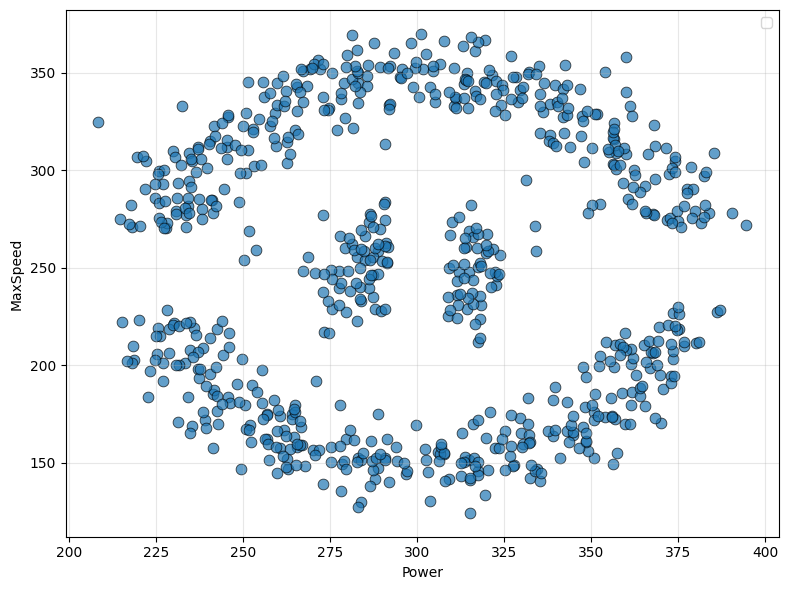

C:\Users\katerina\AppData\Local\Temp\ipykernel_12232\375480535.py:9: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=df,
C:\Users\katerina\AppData\Local\Temp\ipykernel_12232\375480535.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


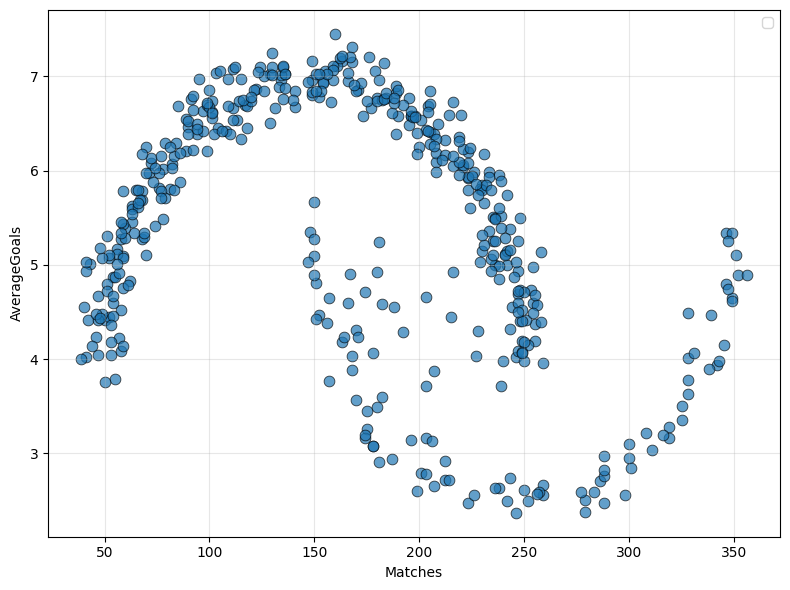

In [4]:
#1.3
import matplotlib.pyplot as plt
import seaborn as sns

def print_scatterplot(df):
    if 'Unnamed: 0' in df.columns:
        df = df.drop('Unnamed: 0', axis=1)

    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=df,
                    x=df.columns[0], 
                    y=df.columns[1],      
                    palette='tab10', 
                    edgecolor='black',
                    alpha=0.7,
                    s=60)

    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    return df

df_arcs = print_scatterplot(df_arcs)
df_moons = print_scatterplot(df_moons)

In [5]:
#1.4
from sklearn.preprocessing import  StandardScaler

def standartize(df, df_name):
    X = df
    scaler_x = StandardScaler()
    X_standard = scaler_x.fit_transform(X)
    print('=' * 7, df_name, '=' * 7)
    print(f"X_standart: {X_standard[:5]}\n")
    return X_standard

X_standard_arcs = standartize(df_arcs, 'df_arcs')
X_standard_moons = standartize(df_moons, 'df_moons')

======= df_arcs =======
X_standart: [[-1.32198668 -0.58135543]
 [-0.86826457  0.89152097]
 [-1.42586119  0.38856666]
 [-1.34833323  0.88438079]
 [-0.43613798  1.10244189]]

======= df_moons =======
X_standart: [[ 0.0596939   1.39304976]
 [-0.27669366  1.08172237]
 [ 0.39608145 -1.68225739]
 [-1.5973263  -0.27748746]
 [-1.06159796  0.38313408]]



Нормализация(MinMaxScaler()) более чувствительна к выбросам в сравнении с стандардизацией, поэтому к данным был применен нормализатор StandardScaler().

2. K-Means:
2.1. Проведите исследование оптимального количества кластеров методов локтя. Сделайте выводы, о наиболее подходящем количестве кластеров.
2.2. Проведите исследование оптимального количества кластеров методом силуэта. Сделайте выводы, о наиболее подходящем количестве кластеров.
2.3. Проведите кластеризацию алгоритмом K-means, с выбранным оптимальным количеством кластеров.
2.4. Постройте диаграмму рассеяния результатов кластеризации с выделением разным цветом разных кластеров.
2.5. Постройте диаграмму Вороного для результатов кластеризации. На диаграмме отметьте центроиды полученных кластеров.
2.6. Постройте для каждого признака диаграмму “box-plot” или “violin-plot”, с разделением по кластерам. Сделайте выводы о разделении кластеров и успешности применения кластеризации K-means к набору данных.
2.7. Рассчитайте для каждого кластера кол-во точек, среднее, СКО, минимум и максимум. Сопоставьте результаты с построенными графиками.


======= KMeans: Метод локтя - df_arcs =======
Оптимальное k=4


======= KMeans: Метод локтя - df_moons =======
Оптимальное k=4




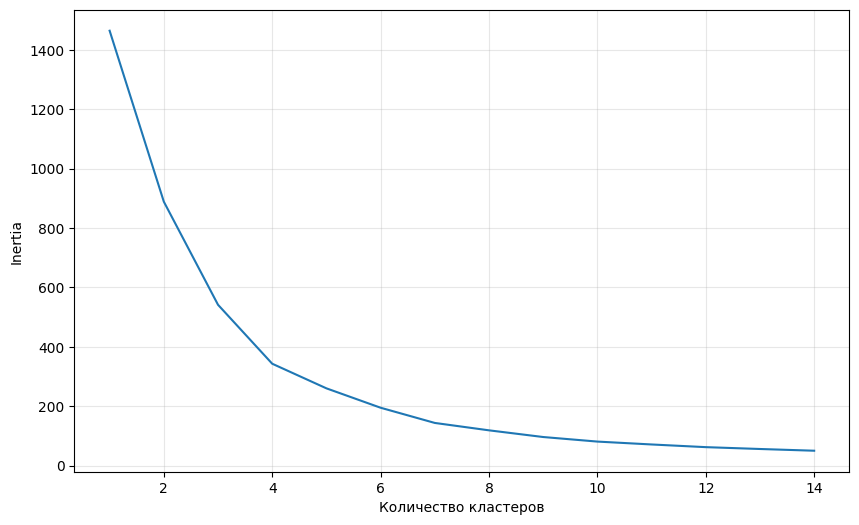

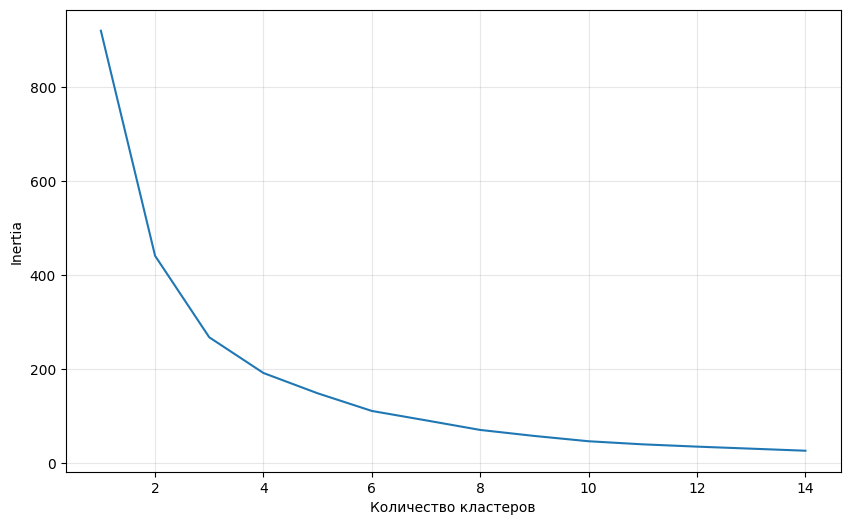

In [170]:
#2.1
from sklearn.cluster import KMeans
from kneed import KneeLocator

def elbow_method(X, df_name):
    print(f"{'='*7} KMeans: Метод локтя - {df_name} {'='*7}")
    inertias = []
    k_range = range(1, 15)
    drops = []

    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)
    
    knee_locator = KneeLocator(
        k_range, inertias,
        curve='convex',
        direction='decreasing',
        S=1.0,
        online=False
    )

    print(f'Оптимальное k={knee_locator.elbow}')    

    print("\n")
    plt.figure(figsize=(10, 6))
    plt.plot(k_range, inertias)
    plt.xlabel('Количество кластеров')
    plt.ylabel('Inertia')
    plt.grid(True, alpha=0.3)


elbow_method(X_standard_arcs, 'df_arcs')
elbow_method(X_standard_moons, 'df_moons')


In [178]:
# 2.2.
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

def silhouette_analysis(X, df_name, k_range=range(2, 21)):
    print(f"\n{'='*7} Метод силуэта - {df_name} {'='*7}")
    
    silhouette_scores = []
    
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X)
        score = silhouette_score(X, labels)
        silhouette_scores.append(score)
        print(f"k = {k:2d} | Silhouette Score: {score:.4f}")
    
    optimal_k = k_range[np.argmax(silhouette_scores)]
    best_score = max(silhouette_scores)
    
    print(f"\nОптимальное количество кластеров: k = {optimal_k}")
    print(f"Лучший silhouette score: {best_score:.4f}")
    
    return optimal_k, best_score, list(k_range), silhouette_scores

optimal_k_arcs, score_arcs, k_range_arcs, sil_arcs = silhouette_analysis(
    X_standard_arcs, 'df_arcs'
)

optimal_k_moons, score_moons, k_range_moons, sil_moons = silhouette_analysis(
    X_standard_moons, 'df_moons'
)


======= Метод силуэта - df_arcs =======
k =  2 | Silhouette Score: 0.3763
k =  3 | Silhouette Score: 0.4064
k =  4 | Silhouette Score: 0.4401
k =  5 | Silhouette Score: 0.4923
k =  6 | Silhouette Score: 0.5062
k =  7 | Silhouette Score: 0.5129
k =  8 | Silhouette Score: 0.5048
k =  9 | Silhouette Score: 0.5029
k = 10 | Silhouette Score: 0.5145
k = 11 | Silhouette Score: 0.5031
k = 12 | Silhouette Score: 0.4873
k = 13 | Silhouette Score: 0.4764
k = 14 | Silhouette Score: 0.4726
k = 15 | Silhouette Score: 0.4597
k = 16 | Silhouette Score: 0.4477
k = 17 | Silhouette Score: 0.4362
k = 18 | Silhouette Score: 0.4246
k = 19 | Silhouette Score: 0.4130
k = 20 | Silhouette Score: 0.4166

Оптимальное количество кластеров: k = 10
Лучший silhouette score: 0.5145

======= Метод силуэта - df_moons =======
k =  2 | Silhouette Score: 0.4691
k =  3 | Silhouette Score: 0.4755
k =  4 | Silhouette Score: 0.4505
k =  5 | Silhouette Score: 0.4459
k =  6 | Silhouette Score: 0.4787
k =  7 | Silhouette Score: 

Поскольку алгоритм K-Means предполагает сферическую (выпуклую) форму кластеров, а наборы данных df_arcs и df_moons имеют вытянутую дугообразную структуру, оптимальное разбиение достигается не минимальным числом кластеров, а таким k, при котором каждая дуга аппроксимируется несколькими компактными кластерами. Визуальный анализ scatter-plot'ов и значения silhouette score подтверждают, что k ≈ 9–10 даёт более устойчивое и интерпретируемое разбиение, чем k=4, предложенное методом локтя. В дальнейшем для данного набора данных будет использовано k = 10 для df_arcs и k=9 для df_moons

In [179]:
# 2.3
from sklearn.cluster import KMeans

k_arcs_final = 10
k_moons_final = 9

kmeans_arcs = KMeans(n_clusters=k_arcs_final, random_state=42, n_init=10)
labels_arcs_kmeans = kmeans_arcs.fit_predict(X_standard_arcs)
centroids_arcs = kmeans_arcs.cluster_centers_ 

kmeans_moons = KMeans(n_clusters=k_moons_final, random_state=42, n_init=10)
labels_moons_kmeans = kmeans_moons.fit_predict(X_standard_moons)
centroids_moons = kmeans_moons.cluster_centers_

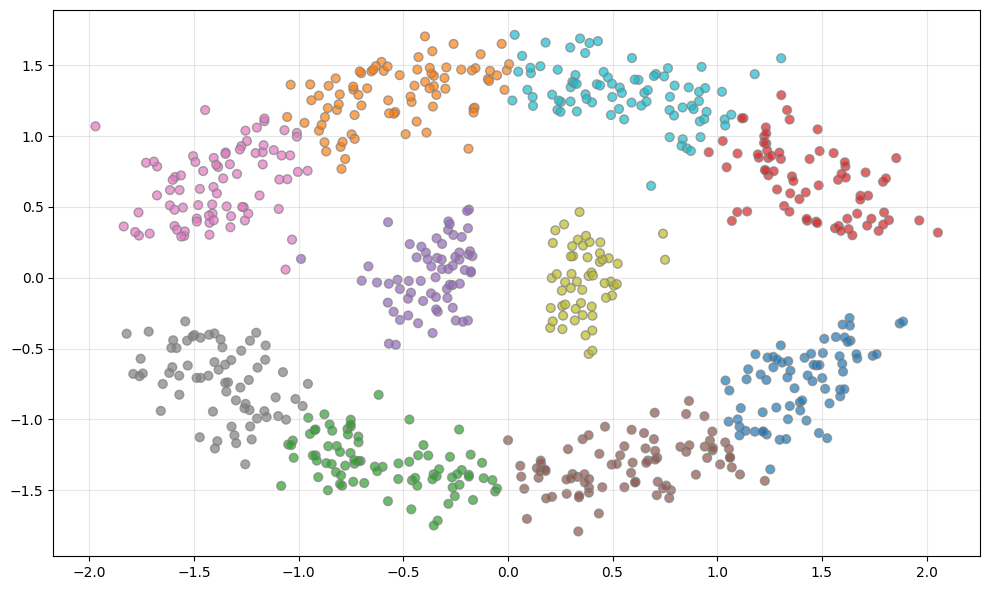

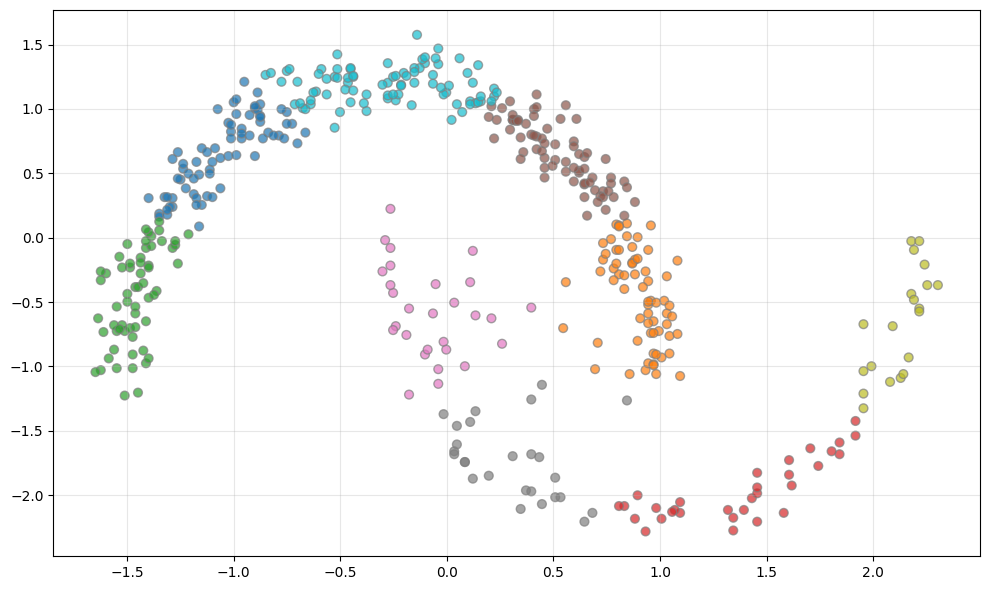

In [181]:
# 2.4.
def plot_clusters(X, labels):
    plt.figure(figsize=(10, 6))
    plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=40, edgecolors='gray', alpha=0.7)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_clusters(X_standard_arcs, labels_arcs_kmeans)
plot_clusters(X_standard_moons, labels_moons_kmeans)

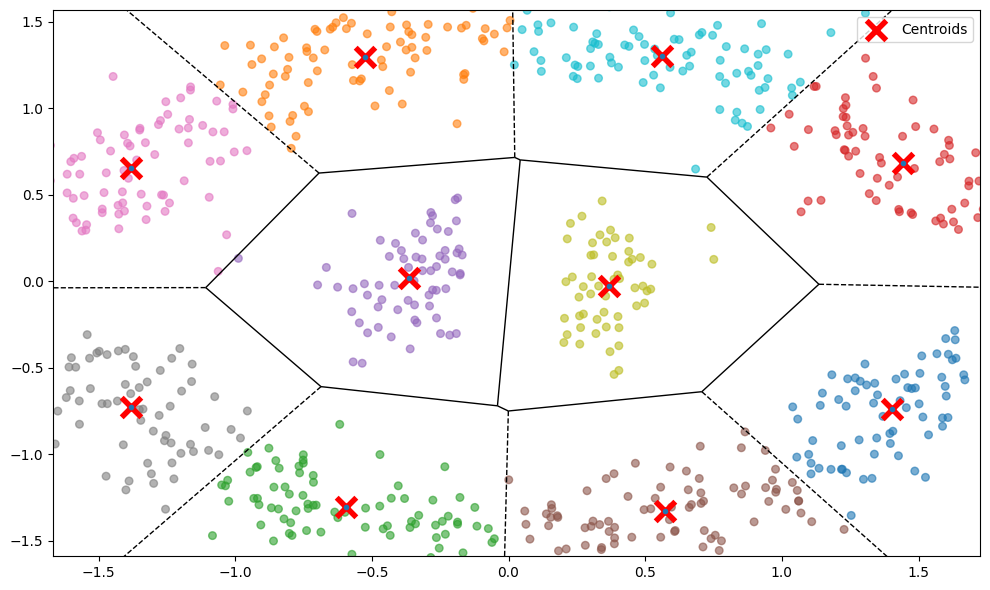

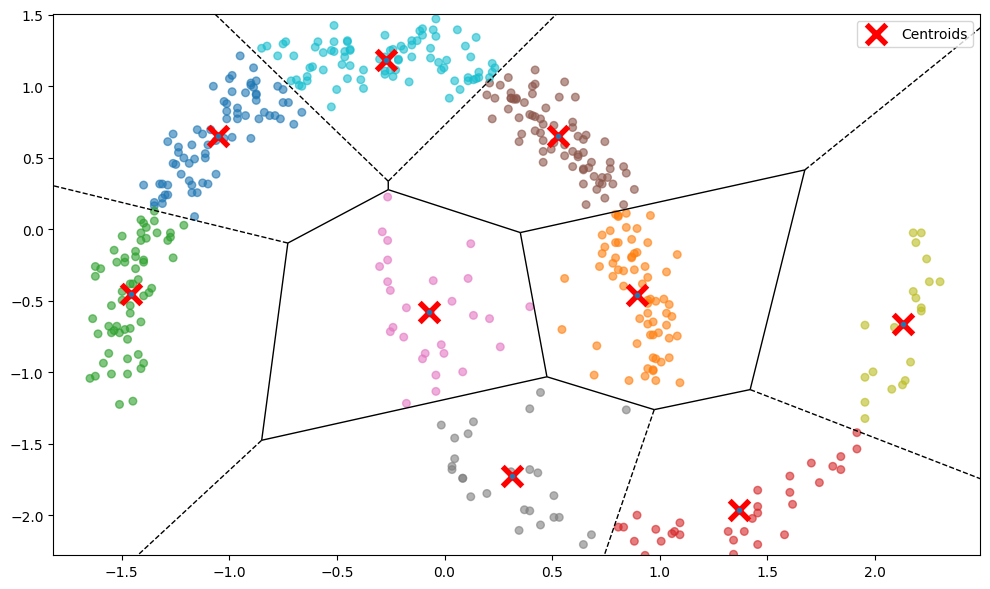

In [184]:
# 2.5
from sklearn.cluster import KMeans
from scipy.spatial import Voronoi, voronoi_plot_2d
import matplotlib.pyplot as plt

def plot_voronoi(X, labels, centroids):
    vor = Voronoi(centroids)  
    plt.figure(figsize=(10, 6))

    plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=30, alpha=0.6)
    voronoi_plot_2d(vor, plt.gca(), line_colors='black', line_width=1, show_vertices=False)
    plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='x', s=200, linewidths=4, label='Centroids')

    plt.legend()
    plt.tight_layout()
    plt.show()


plot_voronoi(X_standard_arcs, labels_arcs_kmeans, centroids_arcs)
plot_voronoi(X_standard_moons, labels_moons_kmeans, centroids_moons)

C:\Users\katerina\AppData\Local\Temp\ipykernel_12232\3191226831.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster', y=feature, data=df_plot, ax=axes[idx], palette='tab10', inner='box')
C:\Users\katerina\AppData\Local\Temp\ipykernel_12232\3191226831.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster', y=feature, data=df_plot, ax=axes[idx], palette='tab10', inner='box')


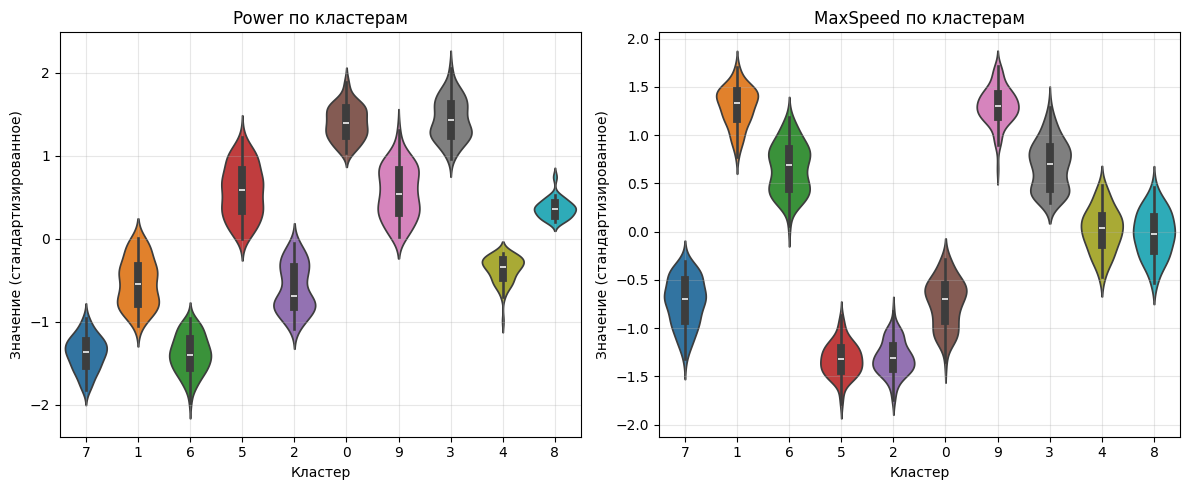

C:\Users\katerina\AppData\Local\Temp\ipykernel_12232\3191226831.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster', y=feature, data=df_plot, ax=axes[idx], palette='tab10', inner='box')
C:\Users\katerina\AppData\Local\Temp\ipykernel_12232\3191226831.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='cluster', y=feature, data=df_plot, ax=axes[idx], palette='tab10', inner='box')


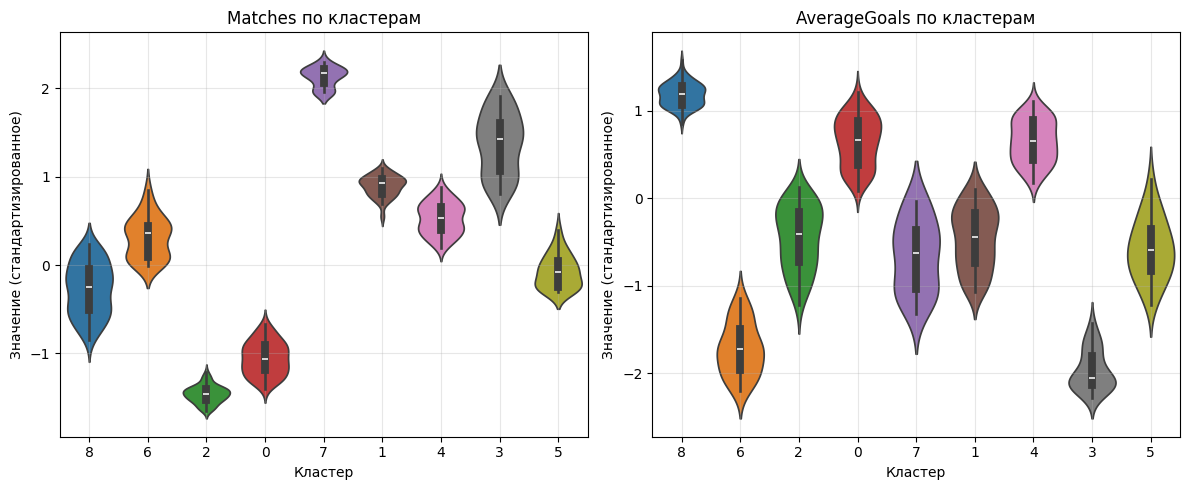

In [186]:
# 2.6
def plot_feature_by_clusters(X, labels, feature_names):
    df_plot = pd.DataFrame(X, columns=feature_names)
    df_plot['cluster'] = labels.astype(str)  
    
    n_features = X.shape[1]
    fig, axes = plt.subplots(1, n_features, figsize=(6*n_features, 5))
    if n_features == 1:
        axes = [axes]
    
    for idx, feature in enumerate(feature_names):
        sns.violinplot(x='cluster', y=feature, data=df_plot, ax=axes[idx], palette='tab10', inner='box')
        axes[idx].set_title(f'{feature} по кластерам')
        
        axes[idx].set_xlabel('Кластер')
        axes[idx].set_ylabel('Значение (стандартизированное)')
        axes[idx].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return df_plot

df_arcs_plot = plot_feature_by_clusters(
    X_standard_arcs, 
    labels_arcs_kmeans,
    feature_names=['Power', 'MaxSpeed']
)
df_moons_plot = plot_feature_by_clusters(
    X_standard_moons, 
    labels_moons_kmeans, 
    feature_names=['Matches', 'AverageGoals']
)

In [188]:
# 2.7.
def calculate_cluster_stats(X, labels, dataset_name, k, feature_names):
    print(f"\n{'='*10} Статистика кластеров: {dataset_name} (k={k}) {'='*10}")
    df_stats = pd.DataFrame(X, columns=feature_names)
    df_stats['Cluster'] = labels
    stats = df_stats.groupby('Cluster').agg(['count', 'mean', 'std', 'min', 'max'])
    print(stats)
    
    return stats

stats_arcs = calculate_cluster_stats(X_standard_arcs, 
                                    labels_arcs_kmeans, 'df_arcs', 
                                    k_arcs_final,
                                    feature_names=['Power', 'MaxSpeed'])
stats_moons = calculate_cluster_stats(X_standard_moons, 
                                    labels_moons_kmeans, 'df_moons', 
                                    k_moons_final,
                                    feature_names=['Matches', 'AverageGoals'])


========== Статистика кластеров: df_arcs (k=10) ==========
        Power                                         MaxSpeed            \
        count      mean       std       min       max    count      mean   
Cluster                                                                    
0          71  1.400912  0.202675  1.039485  1.887973       71 -0.736631   
1          80 -0.526394  0.287800 -1.054634  0.005491       80  1.295170   
2          81 -0.593193  0.287567 -1.083140 -0.051953       81 -1.306493   
3          72  1.442130  0.248247  0.959581  2.054259       72  0.686282   
4          65 -0.365517  0.157039 -0.988336 -0.169649       65  0.018659   
5          80  0.573094  0.312540  0.000740  1.227366       80 -1.325614   
6          79 -1.382747  0.227790 -1.970500 -0.957022       79  0.655367   
7          67 -1.380021  0.207159 -1.821707 -0.955511       67 -0.728816   
8          54  0.368112  0.116124  0.202226  0.750752       54 -0.024247   
9          83  0.561367  0.3

3. DBSCAN:
3.1. Подберите параметры алгоритма DBSCAN, которые на ваш взгляд дают наилучшие результаты. Опишите процесс (почему и как изменяли параметры) подбора параметров.
3.2. Постройте диаграмму рассеяния результатов кластеризации с выделением разным цветом разных кластеров.
3.3. Сделайте выводы об успешности кластеризации.

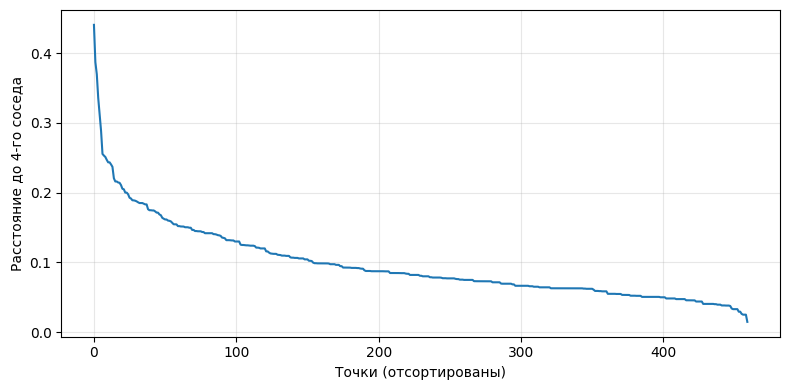

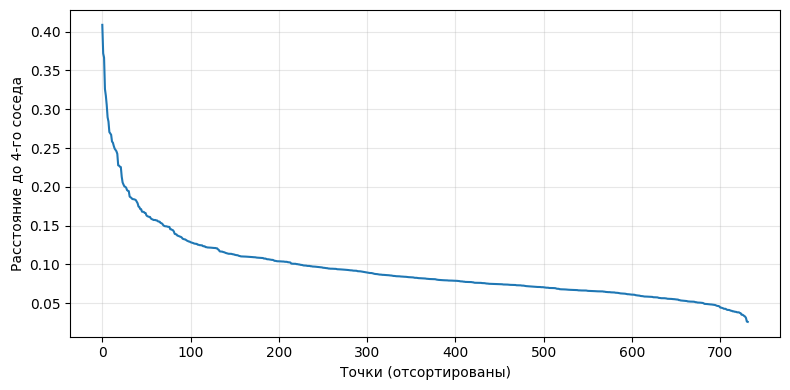

array([0.40880299, 0.37205349, 0.36652784, 0.32601354, 0.31756443,
       0.30554795, 0.28967127, 0.28405002, 0.27061275, 0.26886182,
       0.26714397, 0.25835643, 0.25690945, 0.2526529 , 0.24925698,
       0.24751612, 0.24586389, 0.24251378, 0.22774097, 0.22719515,
       0.22594322, 0.22543776, 0.21300316, 0.20565115, 0.20294371,
       0.20061409, 0.1999607 , 0.19899371, 0.19575185, 0.1949344 ,
       0.19439154, 0.18740587, 0.18643448, 0.18564112, 0.18429927,
       0.18412894, 0.18389337, 0.18352004, 0.1828568 , 0.18077993,
       0.17879389, 0.17461226, 0.17385267, 0.17134829, 0.17116989,
       0.16796832, 0.1678278 , 0.16762115, 0.16643118, 0.16621592,
       0.16320426, 0.16217323, 0.16174244, 0.16126416, 0.16117096,
       0.15921544, 0.15839814, 0.15796772, 0.15726193, 0.15726193,
       0.15725633, 0.15676599, 0.15669189, 0.15557309, 0.15518946,
       0.15509664, 0.15342977, 0.15307885, 0.15233192, 0.15056544,
       0.14966846, 0.1492216 , 0.14910598, 0.14900565, 0.14854

In [116]:
#3.1
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

def plot_k_distance(X, k=4):
    nbrs = NearestNeighbors(n_neighbors=k).fit(X)
    distances, _ = nbrs.kneighbors(X)
    k_distances = np.sort(distances[:, k-1])[::-1]  
    
    plt.figure(figsize=(8, 4))
    plt.plot(k_distances)
    plt.ylabel(f'Расстояние до {k}-го соседа')
    plt.xlabel('Точки (отсортированы)')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return k_distances

plot_k_distance(X_standard_moons, k=4)
plot_k_distance(X_standard_arcs, k=4)

In [162]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import connected_components

def compare_dbscan_eps(X, eps_values, min_samples=5, dataset_name=''):
    results = []
    n_eps = len(eps_values)
    if n_eps == 1:
        axes = [axes]
        
    for i, eps in enumerate(eps_values):
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X)

        mask = labels != -1
        X_filt = X[mask]
        labels_filt = labels[mask]
        
        n_clusters = len(set(labels_filt))
        n_noise = np.sum(labels == -1)

        if n_clusters < 2:
            sil, db, ch = np.nan, np.nan, np.nan
            min_s, max_s, std_s = 0, 0, 0
            conn_ratio = 0.0
        else:
            sil = silhouette_score(X_filt, labels_filt)
            db = davies_bouldin_score(X_filt, labels_filt)
            ch = calinski_harabasz_score(X_filt, labels_filt)
            
            unique, counts = np.unique(labels_filt, return_counts=True)
            min_s, max_s, std_s = counts.min(), counts.max(), counts.std()
            
            connected = 0
            for cid in unique:
                c_pts = X_filt[labels_filt == cid]
                if len(c_pts) < 2:
                    connected += 1
                    continue
                k = min(5, len(c_pts)-1)
                graph = kneighbors_graph(c_pts, n_neighbors=k, mode='connectivity')
                n_comp, _ = connected_components(graph, directed=False)
                if n_comp == 1:
                    connected += 1
            conn_ratio = connected / len(unique)
            
        results.append({
            'eps': eps,
            'n_clusters': n_clusters,
            'n_noise': n_noise,
            'Silhouette': sil,
            'Davies-Bouldin': db,
            'Calinski-Harabasz': ch,
            'Min_Size': min_s,
            'Max_Size': max_s,
            'Size_Std': std_s,
            'Connectivity_Ratio': conn_ratio
        })
    
    return pd.DataFrame(results).round(3)

eps_values = [0.15, 0.2, 0.25]  
table_arcs_dbscan = compare_dbscan_eps(X_standard_arcs, eps_values=eps_values, min_samples=4, dataset_name='df_arcs')
table_moons_dbscan = compare_dbscan_eps(X_standard_moons, eps_values=eps_values, min_samples=4, dataset_name='df_moons')
print("="*15, "Метрики для df_arcs", "="*15)
print(table_arcs_dbscan)
print("\n")
print("="*15, "Метрики для df_moons", "="*15)
print(table_moons_dbscan)

=============== Метрики для df_arcs ===============
    eps  n_clusters  n_noise  Silhouette  Davies-Bouldin  Calinski-Harabasz  \
0  0.15           5       40      -0.020           1.306            142.733   
1  0.20           4       12       0.088           1.199            197.567   
2  0.25           4        3       0.081           1.213            196.099   

   Min_Size  Max_Size  Size_Std  Connectivity_Ratio  
0         5       289   122.820                 1.0  
1        52       308   122.147                 1.0  
2        53       313   123.910                 1.0  


=============== Метрики для df_moons ===============
    eps  n_clusters  n_noise  Silhouette  Davies-Bouldin  Calinski-Harabasz  \
0  0.15          10       41       0.230           0.574             40.356   
1  0.20           6        9       0.158           0.829             83.769   
2  0.25           3        2       0.312           0.899            144.740   

   Min_Size  Max_Size  Size_Std  Connectivi

Параметр min_samples (минимальное количество точек в ε-окрестности для признания точки основной) был выбран на основе стандартной эвристики 2 × dim. Поскольку оба набора данных двумерны (dim = 2), оптимальным значением стало min_samples = 4.
Для подбора параметра eps (радиуса окрестности) был построен график k-расстояний для k = min_samples = 4, а также применён метод «локтя». Дополнительно проводилась визуальная валидация результатов кластеризации для разных значений радиуса.
Для набора df_moons:
Визуальный анализ показывает структуру из двух дуг. Верхняя дуга характеризуется высокой плотностью, и при eps = 0.1 она уже хорошо выделяется в отдельный кластер. Однако нижняя дуга более разрежена, и для объединения её точек требуется больший радиус. При параметрах eps=0.25 и min_samples=4 алгоритм успешно выделил основную структуру данных, разделив их на два крупных кластера (красный и розовый).
Однако на границе нижнего изгиба (правый нижний угол) образовался небольшой изолированный кластер (голубой). Это свидетельствует о том, что плотность точек в этом локальном участке удовлетворяет условию минимума соседей (min_samples), но расстояние до основного розового кластера превышает параметр радиуса eps.
Для набора df_arcs:
Было выбрано аналогичное значение eps = 0.25. Несмотря на более высокую общую плотность данных, в наборе присутствуют разреженные точки (выбросы). При выбранном радиусе эти точки корректно классифицируются как шум или граничные точки, что позволяет сохранить чёткую структуру основных скоплений без чрезмерного «разрастания» кластеров.

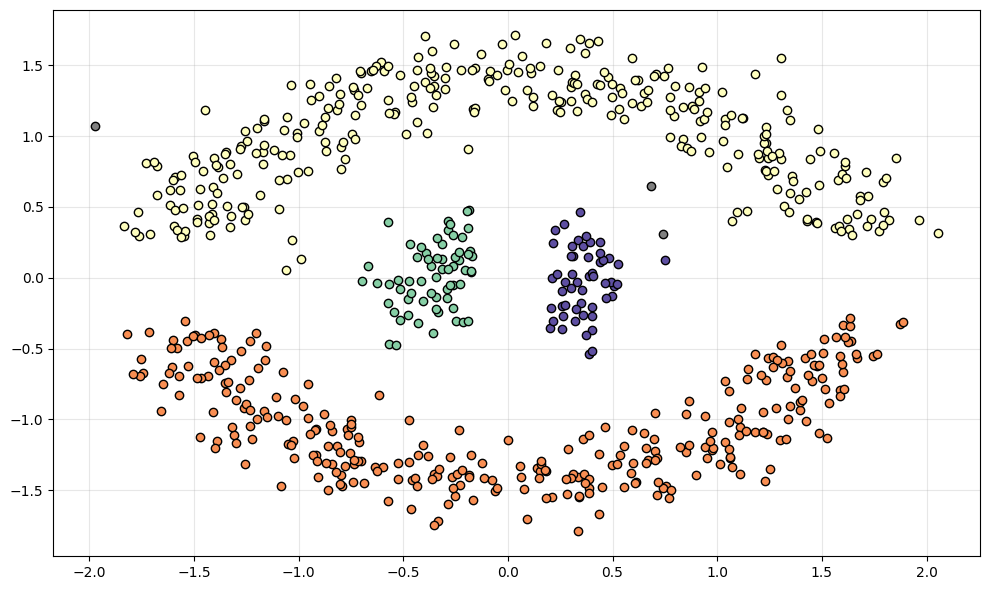

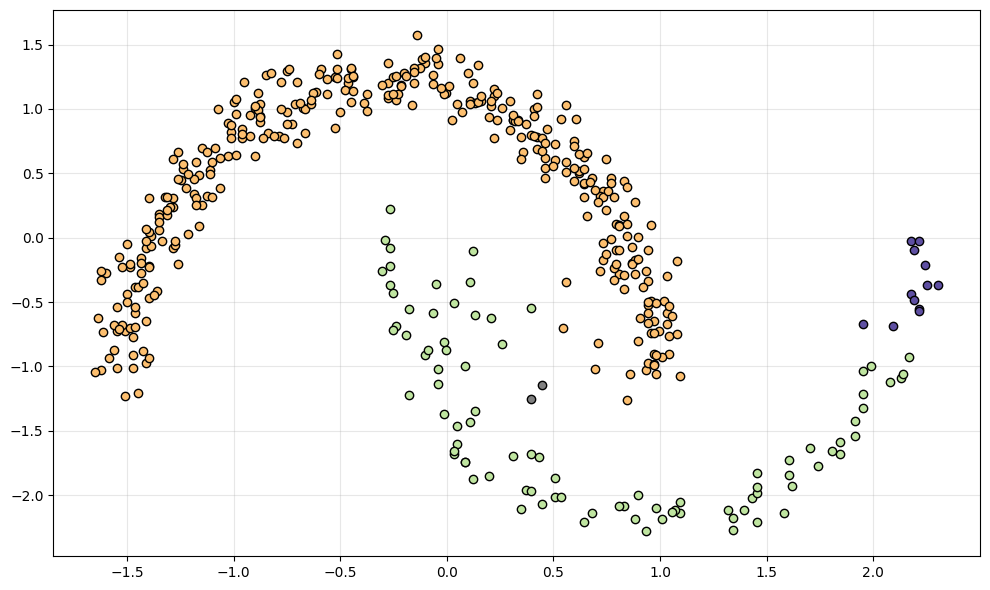

In [164]:
# 3.2
from sklearn.cluster import DBSCAN

def plot_dbscan_results(X, eps, min_samples):
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels = dbscan.fit_predict(X)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    unique_labels = sorted(set(labels))

    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    
    plt.figure(figsize=(10, 6))
    
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = 'gray'

        class_member_mask = (labels == k)
        xy = X[class_member_mask]
        plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col,
                 markeredgecolor='k', markersize=6)
    
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_dbscan_results(X_standard_arcs, eps=0.25, min_samples=4)
plot_dbscan_results(X_standard_moons, eps=0.25, min_samples=4)

Применение алгоритма DBSCAN показало высокую эффективность для данных нелинейной формы (df_arcs и df_moons). В отличие от K-Means, алгоритм успешно распознал вытянутые дуги как единые структуры, не разбивая их на сферические фрагменты. Важным преимуществом стала способность выделять шумовые выбросы (точки между дугами), которые не были отнесены ни к одному кластеру.
Однако процесс выявил и недостатки, связанные с подбором параметра eps. При выбранном значении eps=0.25 для набора df_moons алгоритм корректно выделил верхнюю дугу, но нижняя дуга разделилась на два кластера. Это произошло из-за того, что локальная плотность на конце дуги оказалась ниже порога связности. При попытке увеличить eps для исправления этого разрыва наблюдается нежелательное склеивание кластеров с шумовыми точками. Тем не менее, в целом кластеризация признана успешной, так как основная структура данных была восстановлена лучше, чем в K-Means.

4. Иерархическая кластеризация:
4.1. Проведите иерархическую кластеризацию, подобрав параметр linkage. Постройте дендрограмму. Сделайте выводы, о разделении кластеров и необходимости изменить количество кластеров (если считаете, что необходимо изменить количество кластеров, то повторите кластеризацию с другим количеством кластеров).
4.2. Постройте диаграмму рассеяния результатов кластеризации с выделением разным цветом разных кластеров.
4.3. Сравните результаты кластеризации с результатами полученными в п.2 и п.3. Сделайте выводы о том, какой метод кластеризации подходит под каждый из наборов данных.

In [161]:
#4.1
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import connected_components

def compare_linkages(X, k, linkages=['single', 'complete', 'average', 'ward']):
    results = []
    n_linkages = len(linkages)
    if n_linkages == 1:
        axes = [axes]
        
    for i, linkage in enumerate(linkages):
        model = AgglomerativeClustering(n_clusters=k, linkage=linkage)
        labels = model.fit_predict(X)

        sil = silhouette_score(X, labels)
        db = davies_bouldin_score(X, labels)
        ch = calinski_harabasz_score(X, labels)

        unique, counts = np.unique(labels, return_counts=True)
        min_size, max_size = counts.min(), counts.max()
        size_std = counts.std()

        connected_clusters = 0
        for cid in unique:
            mask = (labels == cid)
            cluster_points = X[mask]
            if len(cluster_points) < 2:
                connected_clusters += 1
                continue
            n_nbrs = min(5, len(cluster_points)-1)
            graph = kneighbors_graph(cluster_points, n_neighbors=n_nbrs, mode='connectivity')
            n_comp, _ = connected_components(graph, directed=False)
            if n_comp == 1:
                connected_clusters += 1
                
        connectivity_ratio = connected_clusters / len(unique)
        
        results.append({
            'Linkage': linkage,
            'Silhouette': sil,
            'Davies-Bouldin': db,
            'Calinski-Harabasz': ch,
            'Min_Size': min_size,
            'Max_Size': max_size,
            'Size_Std': size_std,
            'Connectivity_Ratio': connectivity_ratio
        })
    
    return pd.DataFrame(results).round(3)
 
comparison_table_arcs = compare_linkages(X_standard_arcs, k=4)
comparison_table_moons = compare_linkages(X_standard_moons, k=2)
print("="*15, "Метрики для df_arcs", "="*15)
print(comparison_table_arcs)
print("\n")
print("="*15, "Метрики для df_moons", "="*15)
print(comparison_table_moons )


=============== Метрики для df_arcs ===============
    Linkage  Silhouette  Davies-Bouldin  Calinski-Harabasz  Min_Size  \
0    single       0.011           1.106            169.029         1   
1  complete       0.359           0.797            519.897       122   
2   average       0.421           0.790            677.647       143   
3      ward       0.379           0.761            569.630        97   

   Max_Size  Size_Std  Connectivity_Ratio  
0       378   159.096                1.00  
1       332    86.409                0.75  
2       290    61.834                0.75  
3       336    93.587                0.75  


=============== Метрики для df_moons ===============
    Linkage  Silhouette  Davies-Bouldin  Calinski-Harabasz  Min_Size  \
0    single      -0.011           1.087              1.623         2   
1  complete       0.458           0.887            478.114       187   
2   average       0.458           0.882            471.297       172   
3      ward       0.458 

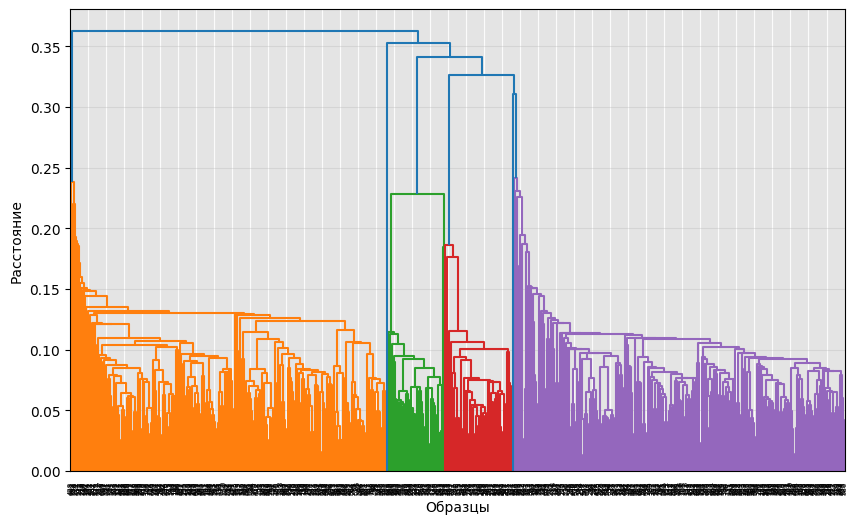

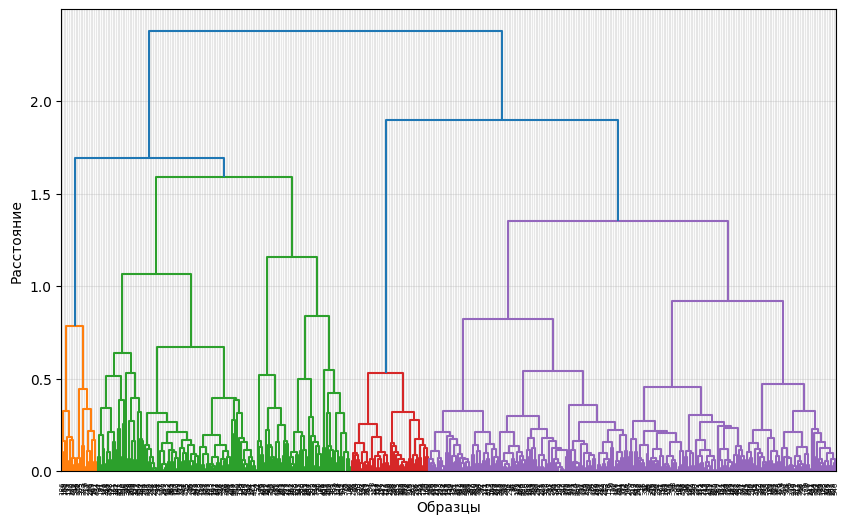

In [140]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

def plot_dendrogram(X, df_name, method):
    plt.figure(figsize=(10, 6))
    Z = linkage(X, method=method)
    dendrogram(Z)
    plt.title(f'Дендрограмма для {df_name} (linkage={method})')
    plt.xlabel('Образцы')
    plt.ylabel('Расстояние')
    plt.grid(True, alpha=0.3)
    plt.show()
    

plot_dendrogram(X_standard_arcs, 'df_arcs', 'single')
plot_dendrogram(X_standard_moons, 'df_moons', 'average')

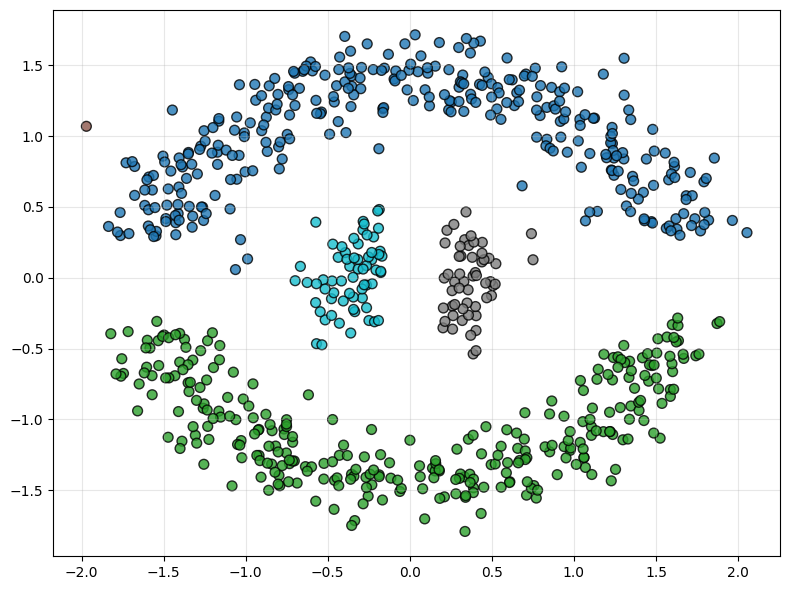

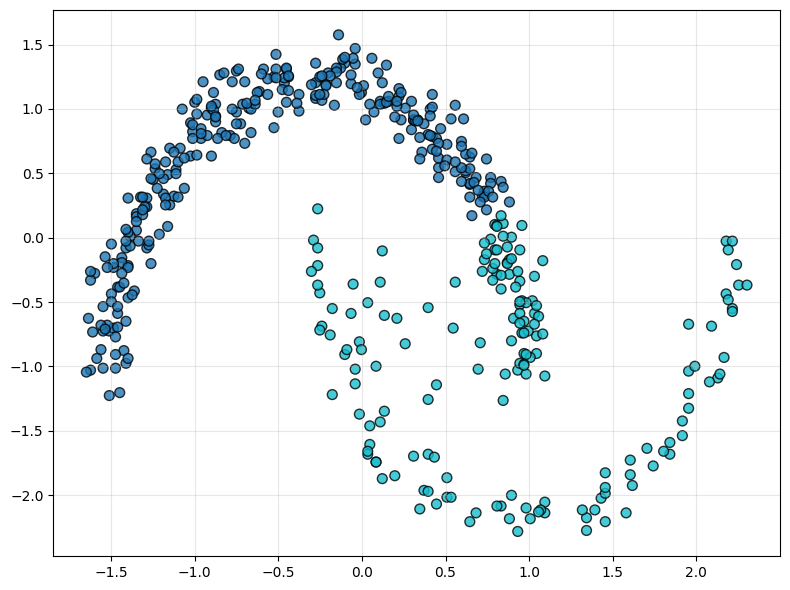

In [167]:
# 4.2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import AgglomerativeClustering

def plot_hierarchical_results(X, n_clusters, linkage, df_name=''):
    clustering = AgglomerativeClustering(
        n_clusters=n_clusters,
        linkage=linkage
    )
    labels = clustering.fit_predict(X)
    
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[:, 0], X[:, 1], 
                         c=labels, 
                         cmap='tab10',  
                         alpha=0.8,
                         s=50,
                         edgecolors='black')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return labels
    
labels_arcs_hier = plot_hierarchical_results(
    X_standard_arcs, 
    n_clusters=5, 
    linkage='single', 
    df_name='df_arcs'
)

labels_moons_hier = plot_hierarchical_results(
    X_standard_moons, 
    n_clusters=2, 
    linkage='ward', 
    df_name='df_moons'
)

In [127]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import pandas as pd

def compare_metrics(X, labels, method_name, dataset_name):
    if method_name == 'DBSCAN':
        mask = labels != -1
        X_filtered = X[mask]
        labels_filtered = labels[mask]
        if len(set(labels_filtered)) < 2:
            return None
    else:
        X_filtered = X
        labels_filtered = labels

    sil = silhouette_score(X_filtered, labels_filtered)
    db = davies_bouldin_score(X_filtered, labels_filtered)
    ch = calinski_harabasz_score(X_filtered, labels_filtered)

    return {
        'Dataset': dataset_name,
        'Method': method_name,
        'Silhouette': sil,
        'Davies-Bouldin': db,
        'Calinski-Harabasz': ch
    }

results = []

results.append(compare_metrics(X_standard_arcs, labels_arcs_kmeans, 'K-Means', 'arcs'))
results.append(compare_metrics(X_standard_arcs, labels_arcs_dbscan, 'DBSCAN', 'arcs'))
results.append(compare_metrics(X_standard_arcs, labels_arcs_hier, 'Hierarchical', 'arcs'))

results.append(compare_metrics(X_standard_moons, labels_moons_kmeans, 'K-Means', 'moons'))
results.append(compare_metrics(X_standard_moons, labels_moon_dbscan, 'DBSCAN', 'moons'))
results.append(compare_metrics(X_standard_moons, labels_moons_hier, 'Hierarchical', 'moons'))

df_results = pd.DataFrame(results)
display(df_results)

,Dataset,Method,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,arcs,K-Means,0.514463,0.612830,1373.300627
1,arcs,DBSCAN,0.081274,1.213315,196.098996
2,arcs,Hierarchical,0.477321,0.678665,831.041262
3,moons,K-Means,0.499285,0.630145,837.522003
4,moons,DBSCAN,0.311602,0.898710,144.739534
5,moons,Hierarchical,0.458137,0.881627,471.296615
